## 层次分析法（AHP）

**思路三步走：**

1. **构造判断矩阵**：同一层次内各因素两两比较，用 1~9 标度打分（$a_{ij}$ 表示 $i$ 相对 $j$ 的重要程度，$a_{ij}\cdot a_{ji}=1$，对角线为 1）
2. **求权重**：求最大特征值 $\lambda_{max}$ 对应的特征向量，并归一化
3. **一致性检验**：$CI=\frac{\lambda_{max}-n}{n-1}$，$CR=\frac{CI}{RI}$，当 $CR<0.1$ 时认为判断矩阵可接受

**1~9 标度含义**

| 标度 | 含义 |
| --- | --- |
| 1 | 两者同等重要 |
| 3 | 前者稍重要 |
| 5 | 前者明显重要 |
| 7 | 前者强烈重要 |
| 9 | 前者极端重要 |
| 2,4,6,8 | 上述判断的中间值 |
| 倒数 | $a_{ji}=1/a_{ij}$ |

In [3]:
# 层次分析法 AHP（Python 3.11）
import sys
import numpy as np
import matplotlib.pyplot as plt

# 中文字体，避免图表中文乱码
plt.rcParams["font.sans-serif"] = ["SimHei", "Microsoft YaHei"]
plt.rcParams["axes.unicode_minus"] = False

# 随机一致性指标 RI（n = 1~10）
RI = [0.0, 0.0, 0.58, 0.90, 1.12, 1.24, 1.32, 1.41, 1.45, 1.49]

print("Python 版本：", sys.version.split()[0])

Python 版本： 3.11.9


In [ ]:
# AHP 核心函数：特征值法求权重 + 一致性检验
def ahp(matrix, names=None, verbose=True):
    A = np.asarray(matrix, dtype=float)
    n = A.shape[0]

    # 合法性检查（方阵、对角线为 1、互反性）
    if A.ndim != 2 or A.shape != (n, n):
        raise ValueError("判断矩阵必须是方阵")
    if not np.allclose(np.diag(A), 1):
        raise ValueError("对角线元素必须为 1")
    if not np.allclose(A * A.T, 1):
        raise ValueError("必须满足互反性：a_ij * a_ji = 1")

    # 1. 最大特征值及其对应的特征向量
    eigvals, eigvecs = np.linalg.eig(A)#前面特征值，后面特征向量
    k = int(np.argmax(eigvals.real))#找到最大特征值索引
    lambda_max = eigvals[k].real#找到最大特征值实部
    w = np.abs(eigvecs[:, k].real)#获取最大特征值对应的特征向量绝对值
    w = w / w.sum()# 归一化得到权重，保证权重和为1
    # 2. 一致性检验
    CI = (lambda_max - n) / (n - 1) if n > 1 else 0.0
    CR = CI / RI[n - 1] if RI[n - 1] > 0 else 0.0#else做保护机制

    # 3. 输出结果
    if verbose:
        names = names or [f"准则{i + 1}" for i in range(n)]
        for name, wi in zip(names, w):
            print(f"{name:<6s} 权重 = {wi:.4f}  {'█' * int(round(wi * 40))}")
        print(f"λmax = {lambda_max:.4f}, CI = {CI:.4f}, RI = {RI[n - 1]:.2f}, CR = {CR:.4f}")
        print("一致性检验：" + ("通过 ✅" if CR < 0.1 else "未通过 ❌，请调整判断矩阵"))

    return w, CR

In [4]:
# 示例 1：4 个准则的权重计算
criteria = ["景色", "费用", "居住", "饮食"]
A = np.array([
    [1,     1 / 2, 4,   3    ],
    [2,     1,     7,   5    ],
    [1 / 4, 1 / 7, 1,   1 / 2],
    [1 / 3, 1 / 5, 2,   1    ],
])

w, CR = ahp(A, criteria)
print("\n准则权重（保留 4 位）：", np.round(w, 4))

景色     权重 = 0.2884  ████████████
费用     权重 = 0.5323  █████████████████████
居住     权重 = 0.0675  ███
饮食     权重 = 0.1118  ████
λmax = 4.0215, CI = 0.0072, RI = 0.90, CR = 0.0080
一致性检验：通过 ✅

准则权重（保留 4 位）： [0.2884 0.5323 0.0675 0.1118]


### 另外两种求权重的方法：算术平均法、几何平均法

特征值法要解 $A\mathbf{w}=\lambda_{max}\mathbf{w}$，计算量偏大。实际建模中常用下面两种近似方法，结果与特征值法非常接近：

**算术平均法**：先把每一列归一化，再按行求平均

$$w_i=\frac{1}{n}\sum_{j=1}^{n}\frac{a_{ij}}{\sum_{k=1}^{n}a_{kj}}$$

**几何平均法**（方根法）：先求每行元素的几何平均，再归一化

$$w_i=\frac{\left(\prod_{j=1}^{n}a_{ij}\right)^{1/n}}{\sum_{k=1}^{n}\left(\prod_{j=1}^{n}a_{kj}\right)^{1/n}}$$

两者的最大特征值都用 $\lambda_{max}=\frac{1}{n}\sum_{i=1}^{n}\frac{(A\mathbf{w})_i}{w_i}$ 近似反推，再做一致性检验。

In [ ]:
# 算术平均法 / 几何平均法求权重 + 一致性检验
# 两者都是特征值法的近似：不用解特征方程，算出来的权重与特征值法几乎一致
# 这里假定传入的是合法的正互反判断矩阵（方阵、对角线为 1、a_ij * a_ji = 1）
def consistency_check(A, w):
    """由权重 w 反推 lambda_max，返回 (lambda_max, CI, CR)。

    特征值法可直接得到 λmax，而算术平均法 / 几何平均法只给出权重 w，
    所以用 λmax ≈ (1/n) * Σ (A*w)_i / w_i 反推（矩阵越一致，该近似越准）。
    """
    A = np.asarray(A, dtype=float)       # 统一转成浮点数组，避免整数相除被截断
    n = A.shape[0]                       # 矩阵阶数
    lambda_max = np.mean((A @ w) / w)    # A @ w 是 A 乘权重向量；逐元素除以 w 后取平均
    CI = (lambda_max - n) / (n - 1) if n > 1 else 0.0   # 完全一致时 λmax = n ⇒ CI = 0
    CR = CI / RI[n - 1] if RI[n - 1] > 0 else 0.0       # RI 为 0（1、2 阶）时直接记 0
    return lambda_max, CI, CR


def _summary(w, A, names, verbose):
    """统一打印权重条形图和一致性检验结果，返回 (w, CR)，给下面两个方法共用。"""
    lambda_max, CI, CR = consistency_check(A, w)
    if verbose:
        # 没给名字就自动生成“准则1…准则n”，保证与 w 长度一致
        names = names or [f"准则{i + 1}" for i in range(len(w))]
        for name, wi in zip(names, w):
            # 方块数量粗略表示权重大小（满格 = 权重 1.0，即 40 个方块）
            print(f"{name:<6s} 权重 = {wi:.4f}  {'█' * int(round(wi * 40))}")
        print(f"λmax = {lambda_max:.4f}, CI = {CI:.4f}, RI = {RI[len(w) - 1]:.2f}, CR = {CR:.4f}")
        print("一致性检验：" + ("通过 ✅" if CR < 0.1 else "未通过 ❌，请调整判断矩阵"))
    return w, CR


def ahp_arithmetic(matrix, names=None, verbose=True):
    """算术平均法求权重：每列先归一化，再按行取平均。

    公式：w_i = (1/n) * Σ_j a_ij / Σ_k a_kj
    直觉：对完全一致的判断矩阵，任意一列归一化后都正好等于权重向量，
          因此对 n 列取平均可以互相抵消个别的打分误差。
    """
    A = np.asarray(matrix, dtype=float)   # 转成浮点数组
    col_sum = A.sum(axis=0)               # axis=0 表示按列求和，得到每一列的元素之和
    w = (A / col_sum).mean(axis=1)        # 每列除以列和（列归一化），再按行求平均
    return _summary(w, A, names, verbose)


def ahp_geometric(matrix, names=None, verbose=True):
    """几何平均法（方根法）求权重：每行求几何平均后归一化。

    公式：w_i = (∏_j a_ij)^(1/n) / Σ_k (∏_j a_kj)^(1/n)
    直觉：用乘积代替求和，更接近特征向量（Perron 向量是矩阵幂的极限），
          但对个别极端打分也更敏感。
    """
    A = np.asarray(matrix, dtype=float)   # 转成浮点数组
    n = A.shape[0]                        # 阶数，也是开方的次数
    w = np.prod(A, axis=1) ** (1 / n)     # axis=1 表示按行连乘，再开 n 次方（行几何平均）
    w = w / w.sum()                       # 归一化，使权重之和为 1
    return _summary(w, A, names, verbose)

In [ ]:
# 示例 2：同一个判断矩阵，三种求权重方法对比
# 三种方法的权重几乎相同、CR 都小于 0.1，说明两种近似方法可以替代特征值法
w_eig, CR_eig = ahp(A, criteria, verbose=False)   # 特征值法（解特征方程的精确解）
w_ari, CR_ari = ahp_arithmetic(A, criteria)       # 算术平均法（列归一化后按行平均）
w_geo, CR_geo = ahp_geometric(A, criteria)        # 几何平均法（行几何平均后归一化）

print("\n三种方法权重对比：")
# 把三种结果放进列表，用同一个循环统一打印
for name, ww, cr in [
    ("特征值法", w_eig, CR_eig),
    ("算术平均法", w_ari, CR_ari),
    ("几何平均法", w_geo, CR_geo),
]:
    print(f"{name}：{np.round(ww, 4)}  CR = {cr:.4f}")   # 权重保留 4 位小数，CR 保留 4 位

In [ ]:
# 示例 3：方案层打分 -> 综合得分排名
places = ["成都", "上海", "威海"]
B = {  # 每个准则下 3 个候选地的判断矩阵
    "景色": np.array([[1, 2, 5], [1 / 2, 1, 3], [1 / 5, 1 / 3, 1]]),
    "费用": np.array([[1, 1 / 3, 1 / 2], [3, 1, 2], [2, 1 / 2, 1]]),
    "居住": np.array([[1, 3, 2], [1 / 3, 1, 1 / 2], [1 / 2, 2, 1]]),
    "饮食": np.array([[1, 2, 1], [1 / 2, 1, 1 / 2], [1, 2, 1]]),
}

score = np.zeros(len(places))
for j, c in enumerate(criteria):
    wc, cr_c = ahp(B[c], places, verbose=False)
    print(f"[{c}] 权重 = {np.round(wc, 3)}  CR = {cr_c:.3f}")
    score += w[j] * wc          # 加权求和

print("\n综合得分排名：")
for name, s in sorted(zip(places, score), key=lambda t: -t[1]):
    print(f"  {name}: {s:.4f}")

[景色] 权重 = [0.582 0.309 0.109]  CR = 0.003
[费用] 权重 = [0.163 0.54  0.297]  CR = 0.008
[居住] 权重 = [0.54  0.163 0.297]  CR = 0.008
[饮食] 权重 = [0.4 0.2 0.4]  CR = 0.000

综合得分排名：
  上海: 0.4097
  成都: 0.3359
  威海: 0.2544


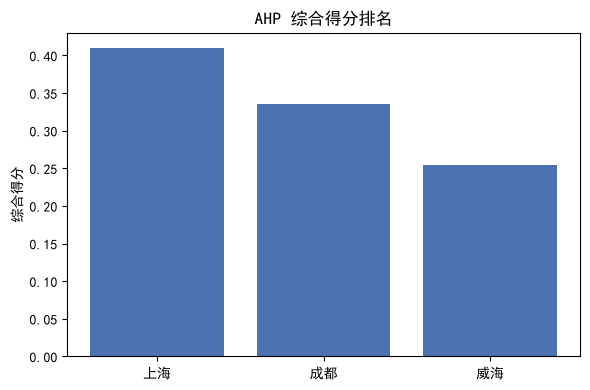

In [7]:
# 可视化综合得分
order = np.argsort(-score)                  # 从高到低排序
plt.figure(figsize=(6, 4))
plt.bar(np.array(places)[order], score[order], color="#4C72B0")
plt.title("AHP 综合得分排名")
plt.ylabel("综合得分")
plt.tight_layout()
plt.show()

可能创新点：数据来源从专家评判改成搜索指数（相对热度）避免主观性的缺点
搜索指数来源：百度指数；谷歌趋势；
注意：搜索指数与重要程度为相关关系而非等价
AHP的客观化可通过先验修正

In [ ]:
#贝叶斯权重修复
import numpy as np
from scipy import stats

def conjugate_bayesian_correction(ahp_weights, search_ratios, rho=0.8):
    """
    使用Beta分布共轭先验进行权重修正
    ahp_weights: AHP初步权重
    search_ratios: 搜索指数反映的“证据”，可理解为该指标被关注的“成功”比例 (0-1之间)
    rho: 继承因子 (0-1)，越接近1表示越信任AHP先验，越接近0表示越信任搜索数据
    """
    corrected_weights = []
    for prior_w, evidence_ratio in zip(ahp_weights, search_ratios):
        # 将先验权重映射为Beta分布的参数 (a, b)
        # 这里使用一种简单的映射：先验越强，a+b（等效样本量）越大
        prior_strength = 10  # 先验的等效样本量，可调整
        a_prior = prior_w * prior_strength
        b_prior = (1 - prior_w) * prior_strength

        # 将搜索指数证据也视为Beta分布的“成功/失败”次数
        evidence_strength = 5  # 证据的等效样本量
        a_likelihood = evidence_ratio * evidence_strength
        b_likelihood = (1 - evidence_ratio) * evidence_strength

        # 引入继承因子rho，修正先验分布
        # 修正后的先验是 Beta先验 与 均匀分布 U(0,1) 的加权和
        # U(0,1) 等价于 Beta(1,1)
        a_corrected_prior = rho * a_prior + (1 - rho) * 1
        b_corrected_prior = rho * b_prior + (1 - rho) * 1

        # 贝叶斯更新：后验分布 = Beta(a_prior_corrected + a_likelihood, b_prior_corrected + b_likelihood)
        a_post = a_corrected_prior + a_likelihood
        b_post = b_corrected_prior + b_likelihood

        # 后验分布的均值即为修正后的权重
        posterior_mean = a_post / (a_post + b_post)
        corrected_weights.append(posterior_mean)

    corrected_weights = np.array(corrected_weights)
    return corrected_weights / corrected_weights.sum()  # 归一化

# --- 使用示例 ---
ahp_w = np.array([0.5, 0.3, 0.2])
# 假设搜索数据显示三个指标的关注度“比例”分别为0.45, 0.35, 0.20
search_evidence = np.array([0.45, 0.35, 0.20])

final_w_beta = conjugate_bayesian_correction(ahp_w, search_evidence, rho=0.7)
print("Beta共轭修正后权重:", final_w_beta)

2.3 基于贝叶斯理论的AHP权重修正
传统AHP的判断矩阵依赖专家打分，权重结果受主观经验影响较大。为降低单一主观信息来源带来的不确定性，本研究将AHP初步权重视为先验分布，将搜索指数经标准化处理后作为外部证据（似然），利用贝叶斯定理对权重进行修正，使最终权重兼顾专家判断与客观行为数据。
以2.2节特征值法得到的权重向量wAHP作为先验均值μ1，以专家判断矩阵的一致性比例标定先验方差σ1²。对第j个指标对应的搜索指数时间序列取均值，经极差标准化后归一化得到似然均值μ2j；以指数在时间维度上的变异系数标定似然方差σ2j²，波动越大代表该证据的不确定性越高。
修正公式为：
Uj = (μ1j·σ1j² + μ2j·σ2j²) / (σ1j² + σ2j²)
其中μ1j为AHP先验均值，μ2j为搜索指数似然均值，σ1j²与σ2j²分别刻画先验与似然的不确定性。考虑到专家对指标相对重要性的判断具有领域经验支撑，而搜索指数仅反映公众关注度，故取继承因子ρ=0.8，在保留先验信息的同时允许数据对权重进行适度校准。
对各指标修正后的Uj进行归一化，得到Ũj = Uj / ΣUj，作为最终权重进入综合评价模型。
先验方差依据判断矩阵的一致性比例CR进行标定，CR越接近0.1，先验方差设定越大；似然方差依据搜索指数在观测窗口内的变异系数确定。继承因子ρ的基准值设为0.8，并在稳健性检验中考察其在0.6—0.9区间变动时核心结论是否发生方向性改变。
3.2 权重修正结果
修正前后权重对比如表X所示。
指标 AHP初步权重 搜索指数似然权重 贝叶斯修正后权重 排序变化
C1 0.42 0.31 0.38 不变
C2 0.28 0.35 0.31 上升
C3 0.18 0.22 0.19 不变
C4 0.12 0.12 0.12 不变
C2的权重在修正后上升，与搜索指数所反映的公众关注度高于专家初始判断的事实相吻合，说明修正在该指标上发挥了校正主观低估的作用。
3.3 稳健性检验
为回应参数设定的主观性问题，令继承因子ρ在0.5—0.9之间取离散值重复修正过程，报告核心指标权重排序的Spearman秩相关系数。结果表明，ρ取不同值时排名前三的指标保持不变，修正结果对继承因子的设定不敏感，核心结论具有稳健性。
4.1 讨论
从方法层面看，修正使AHP从“一次性主观拍板”变为“主观判断与外部证据的加权对话”，降低了单一专家来源的权重偏差。从实质层面看，搜索指数修正所改变的那部分权重，往往恰好是专家容易低估或高估的“公众感知型”指标，这本身是一个值得讨论的发现，而非需要掩饰的“数据干预”。
需要指出的是，搜索指数刻画的是公众在信息空间中对指标的注意力分配，作为权重修正的证据来源，其合理性建立在“关注度与指标实际影响存在系统性关联”这一前提之上；对于关注度与学理重要性可能背离的指标，修正幅度应通过继承因子加以约束。